# <center> **LLM Evaluation** 📝⌛

---

In [1]:
!pip install --upgrade trl -q


[notice] A new release of pip available: 22.2.2 -> 24.2
[notice] To update, run: pip install --upgrade pip


In [2]:
!pip install torch==2.3.0 torchvision==0.18.0 torchaudio==2.3.0 --index-url https://download.pytorch.org/whl/cu121 -q

In [3]:
!pip install "unsloth[colab-new] @ git+https://github.com/unslothai/unsloth.git" -q


[notice] A new release of pip available: 22.2.2 -> 24.2
[notice] To update, run: pip install --upgrade pip


In [4]:
!pip install --no-deps "xformers<0.0.27" "trl<0.9.0" peft accelerate bitsandbytes -q


[notice] A new release of pip available: 22.2.2 -> 24.2
[notice] To update, run: pip install --upgrade pip


In [5]:
!pip install seaborn transformers -q


[notice] A new release of pip available: 22.2.2 -> 24.2
[notice] To update, run: pip install --upgrade pip


## **Set Up**

In [6]:
import torch
from trl import SFTTrainer
from transformers import TextStreamer
from unsloth.chat_templates import get_chat_template
from unsloth import FastLanguageModel, is_bfloat16_supported

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


In [7]:
# Flush CUDA memory
import gc
torch.cuda.empty_cache()
gc.collect()

20

In [8]:
# Load LLM from unsloth 

model_id = input("Enter model ID") #models/ISO-500
if not model_id: model_id = "unsloth/Meta-Llama-3.1-8B-Instruct-bnb-4bit"

max_seq_length = 2048
model, tokenizer = FastLanguageModel.from_pretrained(
    model_name=model_id,
    max_seq_length=max_seq_length,
    load_in_4bit=True,
    dtype=None,
)

Enter model ID 


==((====))==  Unsloth 2024.9.post4: Fast Llama patching. Transformers = 4.45.2.
   \\   /|    GPU: NVIDIA A10G. Max memory: 21.975 GB. Platform = Linux.
O^O/ \_/ \    Pytorch: 2.3.0+cu121. CUDA = 8.6. CUDA Toolkit = 12.1.
\        /    Bfloat16 = TRUE. FA [Xformers = 0.0.26.post1. FA2 = False]
 "-____-"     Free Apache license: http://github.com/unslothai/unsloth


In [9]:
# Define function to call LLM...
def call_LLM(model, tokenizer, messages):

    FastLanguageModel.for_inference(model)

    inputs = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt"
    ).to("cuda")

    text_streamer = TextStreamer(tokenizer)

    output_tensors = model.generate(inputs,
                                    #streamer=text_streamer,
                                    max_new_tokens=128
                                   )
    generated_text = tokenizer.decode(output_tensors[0], skip_special_tokens=True)
    return generated_text

## **Testing** 📝⌛

In [10]:
import re

# Define function to read md question/answer files...
def extract_items_from_md(md_file_path):
    with open(md_file_path, 'r', encoding='utf-8') as file:
        content = file.read()

    questions = re.split(r'\n\d+\.\s', content)
    questions = questions[1:]
    questions = [f"{i+1}. {q.strip()}" for i, q in enumerate(questions)]

    return questions

In [11]:
import os

# Read q/a files and structure them in a dictionary
test_formats = [f.split(".md")[0] for f in os.listdir("exams/questions") if not f.startswith(".")]
tests = {test_format: {} for test_format in test_formats}

for test_format in test_formats:
    questions = extract_items_from_md(os.path.join("exams/questions", test_format+".md"))
    answers = extract_items_from_md(os.path.join("exams/answers", test_format+".md"))

    if len(questions) != len(answers): raise TypeError('Question and answer lists must have same length!')
    else: N = len(questions)

    for i in range(N):
        tests[test_format][str(i+1)] = {'question': questions[i], 'correct-answer': answers[i]}

In [12]:
import re
from difflib import SequenceMatcher

# Define functions to compare LLM responses to correct answers...

def check_true_false(llm_response, correct_answer):
    # Normalize the LLM response to lowercase and remove any extra characters
    llm_response_clean = llm_response.lower()

    # If both "true" and "false" appear in the response, it's automatically wrong
    if 'verdadero' in llm_response_clean and 'false' in llm_response_clean:
        return False

    # Extract the LLM's answer using a regular expression to match "verdadero" or "false"
    match = re.search(r'(true|false)', llm_response_clean)

    if match:
        llm_answer = match.group(1).capitalize()
        return llm_answer == correct_answer
    else:
        return False

def check_mult_choice(llm_response, correct_answer):
    # Normalize the LLM response to lowercase
    llm_response_clean = llm_response.lower()

    # Use regex to find all occurrences of a, b, c, or d in the response
    matches = re.findall(r'[a-d]\)', llm_response_clean)

    # If more than one option is found in the response, return False
    if len(matches) != 1:
        return False

    # Extract the first and only match, then compare it to the correct answer
    llm_answer = matches[0].lower()
    return llm_answer == correct_answer.lower()

In [13]:
from transformers import AutoTokenizer, AutoModel
import torch.nn.functional as F
import torch

lm_tokenizer = AutoTokenizer.from_pretrained('sentence-transformers/all-MiniLM-L6-v2')
lm_model = AutoModel.from_pretrained('sentence-transformers/all-MiniLM-L6-v2')

def get_embedding(text):
    # Tokenize and get embeddings
    inputs = lm_tokenizer(text, return_tensors='pt', truncation=True, padding=True)
    with torch.no_grad():
        outputs = lm_model(**inputs)

    # Use the mean of the last hidden state as the sentence embedding
    return outputs.last_hidden_state.mean(dim=1)

def cosine_similarity(emb1, emb2):
    # Compute cosine similarity between two embeddings
    return F.cosine_similarity(emb1, emb2)

def check_sentence_similarity(llm_response, correct_answer, threshold=0.8):
    # Get embeddings for both the LLM response and the correct answer
    llm_response_emb = get_embedding(llm_response)
    correct_answer_emb = get_embedding(correct_answer)

    # Compute cosine similarity
    similarity = cosine_similarity(llm_response_emb, correct_answer_emb)

    # Return True if similarity is above the threshold, otherwise False
    return similarity.item() >= threshold

In [14]:
%%time
from tqdm.notebook import tqdm

# Go through every q/a pair in each test...

grades = {test_format: {} for test_format in test_formats}
for format_, test in tests.items():
    
    grade = 0
    for id_, qa in tqdm(test.items(), leave=True, desc=f'Testing {format_}'):
        
        # Prompt LLM
        instruction = """
        You are specialist in International Standard for Requirements engineering.

        Please, follow this instructions to answer:
        If you are given a multiple choice question, answer like this: 'The correct answer is <a)/b)/c)/d)>', without giving any additional information or justification.
        If you are given a True or False question, answer like this: 'The correct answer is <True/False>', without giving any additional information or justification.
        If you are given an open-ended question, develop a clear and concise answer in no more than 50 words."
        """
        
        question = qa['question']
        
        msgs = [
            {"role": "system", "content": instruction},
            {"role": "human", "content": question}
        ]
        
        # Ask the test question to the LLM
        llm_response = call_LLM(model, tokenizer, msgs).split('assistant')[1].strip()
        correct_answer = qa['correct-answer']
        
        print(f"\033[1mQuestion:\033[0m {question}")
        print(f"\033[1mCorrect answer:\033[0m {correct_answer}")
        print(f"\033[1mLLM answer:\033[0m {llm_response}" )
        
        # Compare model response with correct answer
        
        if format_=="true-or-false":
            if check_true_false(llm_response, correct_answer.split(". ")[1]): 
                grade += 1
                tests[format_][id_]['result'] = 1
                print("\033[1mResult\033[0m: correct")
            else:
                tests[format_][id_]['result'] = 0
                print("\033[1mResult\033[0m: incorrect")
                
        elif format_=="multiple-choice":
            if check_mult_choice(llm_response, correct_answer.split(". ")[1]): 
                grade += 1
                tests[format_][id_]['result'] = 1
                print("\033[1mResult\033[0m: correct")
            else:
                tests[format_][id_]['result'] = 0
                print("\033[1mResult\033[0m: incorrect")

        else:
            if check_sentence_similarity(llm_response, correct_answer): 
                grade += 1
                tests[format_][id_]['result'] = 1
                print("\033[1mResult\033[0m: correct")
            else:
                tests[format_][id_]['result'] = 0
                print("\033[1mResult\033[0m: incorrect")
        
        # Store model answer in tests dict
        tests[format_][id_]['llm-answer'] = llm_response
        print("-"*50)
        
    # Store grade in grades dict
    grades[format_] = grade/len(test)

Testing true-or-false:   0%|          | 0/20 [00:00<?, ?it/s]

The attention mask is not set and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


Question: 1. The IEEE Standards Association independently evaluates the accuracy of the information in its standards. True o False?
Correct answer: 1. False
LLM answer: The correct answer is True.
Result: incorrect
--------------------------------------------------
Question: 2. Conformance to the ISO/IEC/IEEE 29148 standard implies that no additional information items are required beyond those listed. True o False?
Correct answer: 2. False
LLM answer: The correct answer is False.
Result: correct
--------------------------------------------------
Question: 3. ISO/IEC/IEEE 29148 specifies the processes that are to be implemented for requirements engineering throughout a system's life cycle. True o False?
Correct answer: 3. True
LLM answer: The correct answer is True.
Result: correct
--------------------------------------------------
Question: 4. Tailored conformance allows for modification of the requirements in accordance with project needs. True o False?
Correct answer: 4. True
LLM ans

Testing open-ended:   0%|          | 0/20 [00:00<?, ?it/s]

Question: 1. Describe the role of the ISO/IEC/IEEE 29148 standard in the requirements engineering process.
Correct answer: 1. The ISO/IEC/IEEE 29148 standard provides a unified approach for the processes and products involved in requirements engineering throughout the life cycle of systems and software. It specifies required processes, guidelines for applying these processes, and defines the required information items and their content, ensuring conformance with standards like ISO/IEC 15288 and 12207.
LLM answer: The ISO/IEC/IEEE 29148 standard, also known as Systems and software engineering—Life cycle processes—Requirements engineering, provides a framework for the requirements engineering process. It defines the activities, tasks, and techniques necessary to plan, perform, and manage requirements engineering. The standard ensures that requirements are complete, consistent, and unambiguous, facilitating effective communication and collaboration among stakeholders.
Result: correct
----

Testing multiple-choice:   0%|          | 0/20 [00:00<?, ?it/s]

Question: 1. What is the main task of ISO/IEC JTC 1?
- a) To prepare guidelines for hardware development
- b) To prepare International Standards
- c) To ensure global marketing strategies
- d) To evaluate the performance of ISO members
Correct answer: 1. b)
LLM answer: The correct answer is b) To prepare International Standards.
Result: correct
--------------------------------------------------
Question: 2. Which of the following standards does ISO/IEC/IEEE 29148 harmonize with?
- a) IEEE Std 1012
- b) ISO/IEC TR 19759
- c) IEEE Std 830
- d) All of the above
Correct answer: 2. d)
LLM answer: The correct answer is d).
Result: correct
--------------------------------------------------
Question: 3. Which organization is responsible for administering the consensus development process for IEEE Standards?
- a) ISO
- b) IEC
- c) IEEE
- d) American National Standards Institute
Correct answer: 3. c)
LLM answer: The correct answer is c) IEEE.
Result: correct
-------------------------------------

## **Playground** ▶️🎮

In [15]:
# Prompting
instruction = """
You are specialist in International Standard for Requirements engineering.
you are going to receive questions.
Please, answer the questions with clear and concise responses in no more than 50 words."
"""

# 1st interaction
msgs = [
    {"role": "system", "content": instruction},
    {"role": "human", "content": ""}
]

llm_response = call_LLM(model, tokenizer, msgs).split('assistant')[1]
print(f"\033[1mAssistant:\033[0m {llm_response.strip()}")

# Loop for the conversation
user = 1
while user:
    user = input("\033[1mUser\033[0m:")

    msgs = [
        {"role": "system", "content": instruction},
        {"role": "human", "content": user}
    ]

    llm_response = call_LLM(model, tokenizer, msgs).split('assistant')[1]
    print(f"\033[1mAssistant:\033[0m {llm_response.strip()}")

# Enter grade
print("\n"+"-"*100)
grade = float(input("Evaluate conversation with a number between 0 and 1:"))
grades["chat-eval"] = grade

Assistant: I'll be happy to assist you with questions about International Standards for Requirements Engineering. Go ahead and ask your questions.


User: what is a requirement?


Assistant: According to ISO/IEC 29148 (Software and systems engineering - System and software requirement engineering), a requirement is a condition or capability needed by, or imposed on, a system or product to satisfy a need or constraint, expressed in an unambiguous, verifiable, and quantifiable way.


User: 


Assistant: I'm ready to assist you with International Standards for Requirements Engineering. Please go ahead and ask your questions. I'll provide clear and concise responses in 50 words or less.

----------------------------------------------------------------------------------------------------


Evaluate conversation with a number between 0 and 1: 0.6


## **Final Grades** 💯

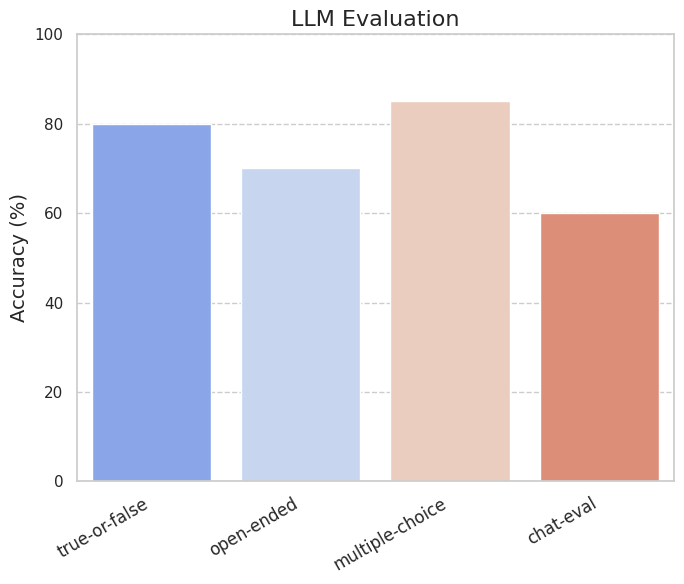

In [16]:
# Plot results
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style="whitegrid")

labels = list(grades.keys())
values = [int(value*100) for value in grades.values()]

plt.figure(figsize=(7, 6))
sns.barplot(x=labels, y=values, palette="coolwarm", hue=labels)

plt.ylabel('Accuracy (%)', fontsize=14)
plt.title('LLM Evaluation', fontsize=16)
plt.xticks(rotation=30, ha="right", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=1)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

In [17]:
import json

# Identify model and save results
file_name = input('Enter file name to store the results:')

file_name = f'exams/results/{file_name}.json'
with open(file_name, 'w') as json_file:
    json.dump(grades, json_file, indent=4)

print(f"Data has been written to {file_name}")

# Print results
print("\nEvaluation Results:")

for test, grade in grades.items():
    print(f"\t- {test}: {round(grade*100)}%")

Enter file name to store the results: ahsdjkas


Data has been written to exams/results/ahsdjkas.json

Evaluation Results:
	- true-or-false: 80%
	- open-ended: 70%
	- multiple-choice: 85%
	- chat-eval: 60%


---